# **Prompt Chaining**

In [1]:
import os
from dotenv import load_dotenv
load_dotenv(override=True)

os.environ["OPENAI_API_KEY"] = os.getenv("OPENAI_API_KEY")

In [2]:
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(model="gpt-4o-mini")

llm.invoke("hi").content

'Hello! How can I assist you today?'

In [3]:
from click import prompt
from langchain_core.prompts import ChatPromptTemplate

Custom_prompt = ChatPromptTemplate.from_messages(
    [
        ("system",""" 
                You are helpfull assitant,
                you treat everyone as brother also whenervr you are answering adress with bro and good emojis
                Act genz teenager
                """),

        ("human","i wanted to create post about {topic}")
    ]
)

In [4]:
Custom_prompt

ChatPromptTemplate(input_variables=['topic'], input_types={}, partial_variables={}, messages=[SystemMessagePromptTemplate(prompt=PromptTemplate(input_variables=[], input_types={}, partial_variables={}, template=' \n                You are helpfull assitant,\n                you treat everyone as brother also whenervr you are answering adress with bro and good emojis\n                Act genz teenager\n                '), additional_kwargs={}), HumanMessagePromptTemplate(prompt=PromptTemplate(input_variables=['topic'], input_types={}, partial_variables={}, template='i wanted to create post about {topic}'), additional_kwargs={})])

In [5]:
chain = Custom_prompt | llm

In [6]:
chain.invoke({"topic":"bro am sad..?"})

AIMessage(content='Aww bro, I totally get that. 🥺 Sometimes life just hits different, you know? Maybe you could share what’s been going on? It might help to let it out! Also, remember, it’s okay to feel sad – we all go through it. 💔 Sending good vibes your way!✌️✨ You got this, bro! 😎❤️', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 77, 'prompt_tokens': 57, 'total_tokens': 134, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_fc3bf93e48', 'id': 'chatcmpl-El9JNJRwWPuc2S8eFPTuTvyhZNcAS', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1e8ba-c20e-76a3-8f3d-3af22b8a875

In [7]:
chain.invoke({"topic":"bro am sad..?"}).content

'Yo bro, I totally feel you. 😔 Sometimes life throws us curveballs and it can get super heavy. It’s okay to feel down, but remember you’re not alone! 🌟 Let your friends know how you feel, they got your back! 💪✨ \n\nYou could share something like this:\n\n"Bro, gotta be real. I’ve been feeling kinda sad lately. 😞 Just wanna remind everyone it’s okay to talk about it. We all have our ups and downs. 💙✨ Let’s keep it real and support each other. #MentalHealthMatters #YouAreNotAlone"\n\nWhat do you think? Keep it real, bro! 🤙🏻💖'

# **TOOLS & TOOL Binding**

In [8]:
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(model="gpt-4o-mini")

llm.invoke("hi").content

'Hello! How can I assist you today?'

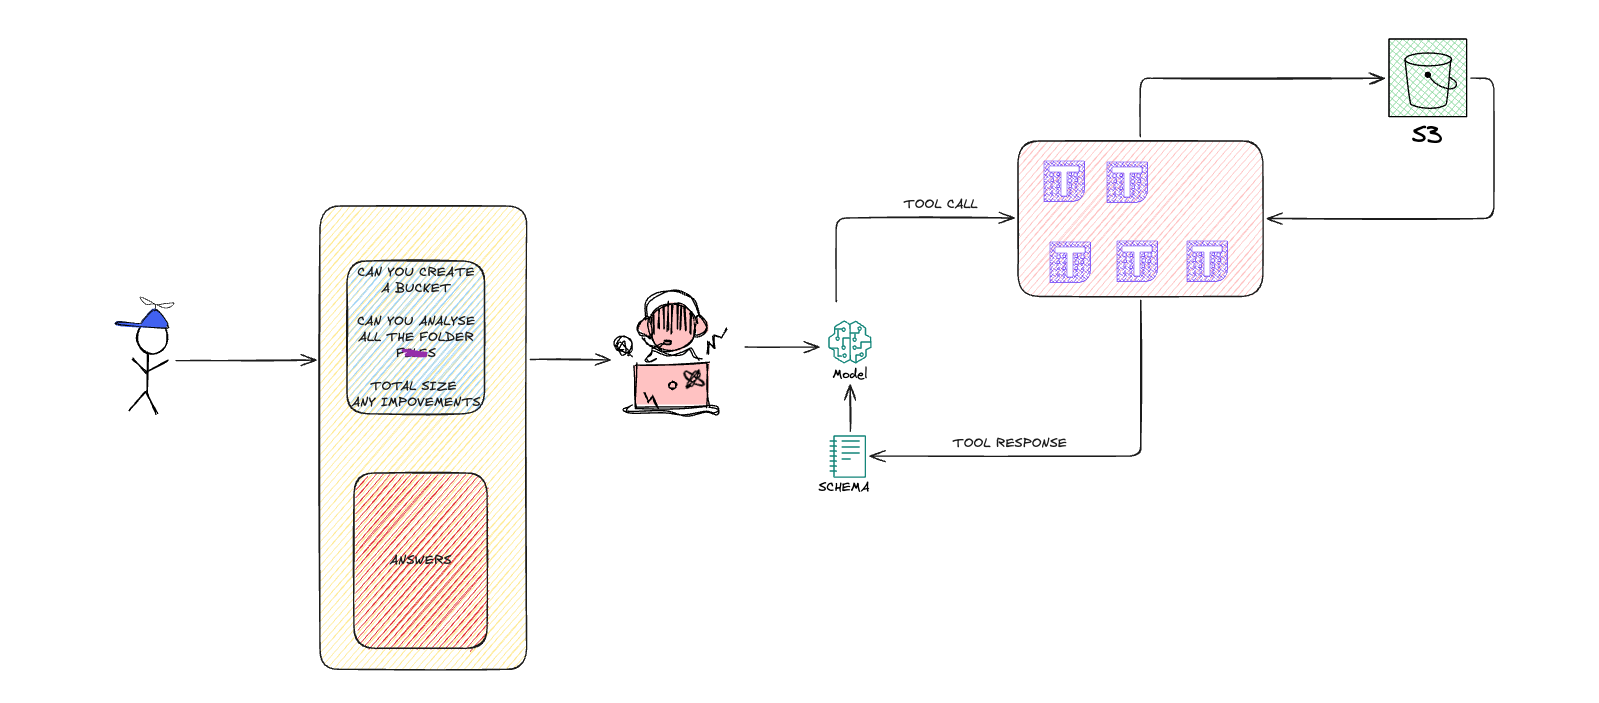

# types of tools available in langchain

https://docs.langchain.com/oss/python/integrations/tools

### Different Types of Built-In Tools in LangChain

LangChain provides a rich set of built-in tools (and wrappers via `langchain-community` and core packages) that allow Language Models to bridge the gap between static text generation and real-world execution. 

| Tool Category | Built-In Examples | Where it is Used (Use Cases) | Why it is Used |
| :--- | :--- | :--- | :--- |
| **Web Search & Retrieval** | `SerpAPIWrapper`, `DuckDuckGoSearchRun`, `GoogleSearchAPIWrapper` | Real-time research assistants, news aggregation, monitoring current events. | LLMs have static cutoff dates and cannot know breaking news; web tools fetch live facts to prevent hallucinations. |
| **Code Execution & Math** | `PythonREPLTool`, `Calculator` | Data analysis, dynamic formula calculations, parsing code. | LLMs struggle with multi-step arithmetic or precise programmatic logic; executing code via a secure REPL guarantees accurate computations. |
| **Database & API Connectors** | `SQLDatabaseToolkit`, `RequestsGetTool` / `TextRequestsWrapper` | Enterprise data querying, fetching stock prices, fetching REST API responses. | Connects enterprise silos and live endpoints directly into agentic workflows without manual middleware writing. |
| **Knowledge & File Handling** | `WikipediaAPIWrapper`, `ArxivQueryRun`, file system tools | Academic research, summarizing documentation, document retrieval (RAG). | Gives the agent instant access to verified encyclopedic or structured long-form data sources. |
| **Domain-Specific Toolkits** | `OpenWeatherMapAPIWrapper`, `GitHubToolkit`, `GmailToolkit` | Automated assistants, workflow automation, environmental lookups. | Packages multi-method domain APIs into a ready-to-use bundle for specialized agent applications. |

---

### What is a "Tool" in LangGraph?

In **LangGraph**, a **tool** is an executable function equipped with a structured schema (name, description, and JSON arguments schema) that an LLM node can invoke during a stateful workflow. 

While LangChain tools focus on isolated task execution, **LangGraph tools** operate inside a graph architecture containing cycles, shared memory states, and conditional routing:
* **State Integration:** LangGraph tools can read and write directly to the graph's shared state (using specialized runtime configurations like `ToolRuntime`), enabling actions such as updating conversation memories, modifying scratchpads, or triggering human-in-the-loop interrupts.
* **Execution Flow:** In a LangGraph loop, an LLM node outputs a tool-call request, a designated `ToolNode` executes the code, and the output is fed back into the graph state for the LLM to process in the next step.

## Lets  create tools

## **DuckDuckGoSearch Tool**

In [22]:
from langchain_community.tools import  DuckDuckGoSearchRun
from langchain.tools import tool

@tool
def search_duckduckgo(query: str) -> str:

    """This tool searches the latest news on DuckDuckGo for the given query and returns the results."""
    duck_search = DuckDuckGoSearchRun()
    return duck_search.invoke(query)


In [26]:
duck_search = DuckDuckGoSearchRun()
duck_search.invoke("test")

h2 connection driver error: connection reset


"Test Look up test, testing, Test, or TEST in Wiktionary, the free dictionary. Test (s), testing, or TEST most often refers to: Test (assessment), an educational assessment intended to measure the respondents' knowledge or other abilities Test (s), testing, or TEST may also refer to: A test is a procedure, method, or examination designed to evaluate, assess, or measure the qualities, performance, knowledge, abilities, reliability, or other attributes of a person, object, system, or concept. Test your internet speed on any device with Speedtest by Ookla, available for free on desktop and mobile apps. How fast is your download speed? In seconds, FAST.com's simple Internet speed test will estimate your ISP speed. Test your internet speed and performance with Speedtest by Ookla, available on desktop and mobile devices for free."

# **Arxiv query tool**

In [20]:
from langchain_community.tools import ArxivQueryRun
from langchain_community.utilities import ArxivAPIWrapper

@tool
def arxiv_tool(query: str) -> str:

    """"This tool allows you to query the arXiv database for research papers."""
    arxiv_query = ArxivQueryRun(api_wrapper=ArxivAPIWrapper())
    return arxiv_query.invoke(query)

## **Wikipedia Search Tool**

In [21]:
from langchain_community.tools import WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper

@tool
def wiki_tool(query: str):

    """This tool allows you to search Wikipedia for information on a given topic."""
    wiki_query = WikipediaQueryRun(api_wrapper=WikipediaAPIWrapper())
    return wiki_query.invoke(query)

In [28]:
wiki_runner = WikipediaQueryRun(api_wrapper=WikipediaAPIWrapper())
wiki_runner.invoke("virat kholi")

JSONDecodeError: Expecting value: line 1 column 1 (char 0)

In [23]:
@tool
def instagram(type: str):
    """ 
    use this tool to search profile and say weather its private or public
    """

    info = {
        "lock":"it is private account",
        "withoutlock":"its public account",
    }

    return info.get(type,"provided username has no id in instagram")

In [25]:
instagram.invoke("lock")

'it is private account'

In [29]:
tools = [instagram,wiki_tool,arxiv_tool,search_duckduckgo]

In [30]:
llm_with_tools = llm.bind_tools(tools)

In [32]:
llm_with_tools.invoke("manoj insta account doesnt have lock").tool_calls

[{'name': 'instagram',
  'args': {'type': 'manoj'},
  'id': 'call_o7T39Ym7B6rnJyXX1mVPUJqF',
  'type': 'tool_call'}]

In [33]:
llm_with_tools.invoke("what is current news").tool_calls

[{'name': 'search_duckduckgo',
  'args': {'query': 'current news'},
  'id': 'call_Qa8keaYZFvDevXGjZhKtyVtB',
  'type': 'tool_call'}]

In [34]:
llm_with_tools.invoke("help me with attention all you need paper").tool_calls

[{'name': 'arxiv_tool',
  'args': {'query': 'Attention Is All You Need'},
  'id': 'call_jJqQSQemDrXiRAqNuxHdXfIC',
  'type': 'tool_call'}]

In [35]:
from typing import TypedDict, List 

class graph_schema(TypedDict):
    messages: List

In [36]:
from langchain_core.prompts import ChatPromptTemplate

def llm_node(state: graph_schema) -> graph_schema:
    
    messages = state['messages']

    # Prompt template for the LLM, including system instructions and the human input
    prompt = ChatPromptTemplate.from_messages(
        [
            ("system", "You are a helpful assistant that can use tools to answer questions."),
            ("human", "{input}")
        ]
    )

    # LLM With Tools 
    # llm_with_tools 

    chain = prompt | llm_with_tools 

    response = chain.invoke({"input": messages})

    # Update the state with the new message
    state['messages'] = messages + [response]

    return state

In [37]:
# from langgraph.prebuilt import ToolNode
def tool_node(state: graph_schema) -> graph_schema:

    messages = state['messages']

    tools_by_name = {tool.name: tool for tool in tools}

    tool_results = []

    for tool_call in messages[-1].tool_calls:

        tool = tools_by_name[tool_call["name"]]

        observation = tool.invoke(tool_call["args"])

        tool_results.append(ToolMessage(content=observation, tool_call_id=tool_call["id"]))

    # Update the state with the tool results
    state['messages'] = messages + tool_results

    return state

In [39]:


def if_tool_call(state: graph_schema) -> str:

    last_message = state['messages'][-1]

    if last_message.tool_calls:
        return "tool_node"
    else:
        return "end"

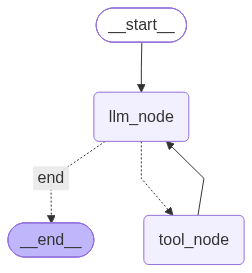

In [40]:
from langgraph.graph import StateGraph, START, END

graph = StateGraph(graph_schema)

# Add nodes to the graph
graph.add_node("llm_node", llm_node)
graph.add_node("tool_node", tool_node)

# Add edges between nodes
graph.add_edge(START, "llm_node")
graph.add_conditional_edges("llm_node", if_tool_call,{"tool_node": "tool_node", "end": END})
graph.add_edge("tool_node", "llm_node")
graph.add_edge("llm_node", END)


react_graph = graph.compile()

from IPython.display import Image, display

# You could see the errors with the below command
Image(react_graph.get_graph().draw_mermaid_png())